<center><h1>Hong_Brandon_HW3</h1></center>
<br>
<br>

Name: Brandon Hong
<br>
Github Username: bwhong
<br>
USC ID: 3091232124

## 1. Time Series Classification Part 1: Feature Creation/Extraction

### (a) Download Data

Package imports

In [132]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_curve, auc, roc_auc_score, confusion_matrix, accuracy_score
import statsmodels.api as sm

Get the AReM Data Set

In [2]:
instances = []
instance_counter = 1

In [3]:
bending1_datasets = []
for i in np.arange(1,8,1):
    bending1_datasets.append('../data/AReM/bending1/' + f'dataset{i}.csv')
for dataset in bending1_datasets:
    temp_dataset = pd.read_csv(dataset, skiprows=4)
    temp_dataset['instance_number'] = instance_counter
    instance_counter += 1
    instances.append(temp_dataset)

In [4]:
bending2_datasets = []
for i in np.arange(1,7,1):
    bending2_datasets.append('../data/AReM/bending2/' + f'dataset{i}.csv')
for dataset in bending2_datasets:
    if dataset == '../data/AReM/bending2/dataset4.csv':
        with open(dataset, "r") as file:
            column_names = file.readlines()[4].strip().split(",")
        temp_dataset = pd.read_csv(dataset, delimiter= ' ', skiprows = 5, names = column_names, index_col=False)
    else:
        temp_dataset = pd.read_csv(dataset, skiprows=4)
    temp_dataset['instance_number'] = instance_counter
    instance_counter += 1
    instances.append(temp_dataset)

In [5]:
cycling_datasets = []
for i in np.arange(1,16,1):
    cycling_datasets.append('../data/AReM/cycling/' + f'dataset{i}.csv')
for dataset in cycling_datasets:
    temp_dataset = pd.read_csv(dataset, skiprows=4, usecols=range(7))
    temp_dataset['instance_number'] = instance_counter
    instance_counter += 1
    instances.append(temp_dataset)

In [6]:
lying_datasets = []
for i in np.arange(1,16,1):
    lying_datasets.append('../data/AReM/lying/' + f'dataset{i}.csv')
for dataset in lying_datasets:
    temp_dataset = pd.read_csv(dataset, skiprows=4, usecols=range(7))
    temp_dataset['instance_number'] = instance_counter
    instance_counter += 1
    instances.append(temp_dataset)

In [7]:
sitting_datasets = []
for i in np.arange(1,16,1):
    sitting_datasets.append('../data/AReM/sitting/' + f'dataset{i}.csv')
for dataset in sitting_datasets:
    temp_dataset = pd.read_csv(dataset, skiprows=4, usecols=range(7))
    temp_dataset['instance_number'] = instance_counter
    instance_counter += 1
    instances.append(temp_dataset)

In [8]:
standing_datasets = []
for i in np.arange(1,16,1):
    standing_datasets.append('../data/AReM/standing/' + f'dataset{i}.csv')
for dataset in standing_datasets:
    temp_dataset = pd.read_csv(dataset, skiprows=4, usecols=range(7))
    temp_dataset['instance_number'] = instance_counter
    instance_counter += 1
    instances.append(temp_dataset)

In [9]:
walking_datasets = []
for i in np.arange(1,16,1):
    walking_datasets.append('../data/AReM/walking/' + f'dataset{i}.csv')
for dataset in walking_datasets:
    temp_dataset = pd.read_csv(dataset, skiprows=4, usecols=range(7))
    temp_dataset['instance_number'] = instance_counter
    instance_counter += 1
    instances.append(temp_dataset)

### (b) Test and Train Data

In [10]:
#test data is first 2 in bending 1 and 2, and then first 3 in every other folder
test_instances = [0,1,7,8,13,14,15,28,29,30,44,45,46, 59, 60, 61, 74, 75, 76]
test_data = pd.concat(instances[i] for i in test_instances)
test_data

,# Columns: time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23,instance_number
0,0,39.25,0.43,22.75,0.43,33.75,1.30,1
1,250,39.25,0.43,23.00,0.00,33.00,0.00,1
2,500,39.25,0.43,23.25,0.43,33.00,0.00,1
3,750,39.50,0.50,23.00,0.71,33.00,0.00,1
4,1000,39.50,0.50,24.00,0.00,33.00,0.00,1
...,...,...,...,...,...,...,...,...
475,118750,34.75,7.66,14.50,2.18,12.00,5.79,77
476,119000,24.75,8.26,13.50,5.02,17.25,4.32,77
477,119250,26.25,2.49,18.75,3.56,12.50,7.09,77
478,119500,38.50,3.28,18.25,2.38,18.50,2.06,77


In [11]:
# train data is everything not in test
train_data = pd.concat(instances[i] for i in range(88) if i not in test_instances)
train_data

,# Columns: time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23,instance_number
0,0,42.00,0.71,21.25,0.43,30.00,0.00,3
1,250,41.50,0.50,20.25,1.48,31.25,1.09,3
2,500,41.50,0.50,14.25,1.92,33.00,0.00,3
3,750,40.75,0.83,15.75,0.43,33.00,0.00,3
4,1000,40.00,0.71,20.00,2.74,32.75,0.43,3
...,...,...,...,...,...,...,...,...
475,118750,34.50,6.18,9.00,3.56,12.67,4.19,88
476,119000,25.75,6.02,13.75,2.05,16.00,1.58,88
477,119250,31.50,3.35,10.25,5.12,16.25,2.95,88
478,119500,33.75,2.77,14.00,3.24,13.75,0.43,88


### (c) Feature Extraction

#### i. Research

Mean, Standard Deviation, Skewness, Kurtosis, Maximum, Minimum, Quantiles, Median

#### ii. Extraction

In [12]:
all_column_names = []
for i in np.arange(1,7,1):
    all_column_names.extend([f'min_{i}', f'max_{i}', f'mean_{i}', f'median_{i}', f'std_{i}', f'1st_quart_{i}', f'3rd_quart_{i}'])
all_column_names

['min_1',
 'max_1',
 'mean_1',
 'median_1',
 'std_1',
 '1st_quart_1',
 '3rd_quart_1',
 'min_2',
 'max_2',
 'mean_2',
 'median_2',
 'std_2',
 '1st_quart_2',
 '3rd_quart_2',
 'min_3',
 'max_3',
 'mean_3',
 'median_3',
 'std_3',
 '1st_quart_3',
 '3rd_quart_3',
 'min_4',
 'max_4',
 'mean_4',
 'median_4',
 'std_4',
 '1st_quart_4',
 '3rd_quart_4',
 'min_5',
 'max_5',
 'mean_5',
 'median_5',
 'std_5',
 '1st_quart_5',
 '3rd_quart_5',
 'min_6',
 'max_6',
 'mean_6',
 'median_6',
 'std_6',
 '1st_quart_6',
 '3rd_quart_6']

In [13]:
extraction = []
for i in np.arange(0,88, 1):
    stats = instances[i].drop(columns = {'# Columns: time', 'instance_number'}).describe().T[['min', 'max', 'mean', '50%', 'std', '25%', '75%']].rename(columns = {'50%':'median', '25%': '1st_quart', '75%': '3rd_quart'}).to_numpy().flatten()
    extraction.append(stats)
time_series_stats = pd.DataFrame(extraction, columns= all_column_names)
time_series_stats.insert(0, 'Instance', np.arange(1,89,1))
time_series_stats

,Instance,min_1,max_1,mean_1,median_1,std_1,1st_quart_1,3rd_quart_1,min_2,max_2,...,std_5,1st_quart_5,3rd_quart_5,min_6,max_6,mean_6,median_6,std_6,1st_quart_6,3rd_quart_6
0,1,37.25,45.00,40.624792,40.50,1.476967,39.25,42.0000,0.0,1.30,...,2.188449,33.0000,36.00,0.00,1.92,0.570583,0.43,0.582915,0.0000,1.3000
1,2,38.00,45.67,42.812812,42.50,1.435550,42.00,43.6700,0.0,1.22,...,1.995255,32.0000,34.50,0.00,3.11,0.571083,0.43,0.601010,0.0000,1.3000
2,3,35.00,47.40,43.954500,44.33,1.558835,43.00,45.0000,0.0,1.70,...,1.999604,35.3625,36.50,0.00,1.79,0.493292,0.43,0.513506,0.0000,0.9400
3,4,33.00,47.75,42.179812,43.50,3.670666,39.15,45.0000,0.0,3.00,...,3.849448,30.4575,36.33,0.00,2.18,0.613521,0.50,0.524317,0.0000,1.0000
4,5,33.00,45.75,41.678063,41.75,2.243490,41.33,42.7500,0.0,2.83,...,2.411026,28.4575,31.25,0.00,1.79,0.383292,0.43,0.389164,0.0000,0.5000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
83,84,19.50,45.33,33.586875,34.25,4.650935,30.25,37.0000,0.0,14.67,...,3.283983,13.7300,18.25,0.00,8.32,3.259729,3.11,1.640243,2.0500,4.3225
84,85,19.75,45.50,34.322750,35.25,4.752477,31.00,38.0000,0.0,13.47,...,3.119856,13.5000,17.75,0.00,9.67,3.432563,3.20,1.732727,2.1575,4.5650
85,86,19.50,46.00,34.546229,35.25,4.842294,31.25,37.8125,0.0,12.47,...,2.823124,14.0000,17.75,0.00,10.00,3.338125,3.08,1.656742,2.1600,4.3350
86,87,23.50,46.25,34.873229,35.25,4.531720,31.75,38.2500,0.0,14.82,...,3.131076,13.7500,18.00,0.00,9.51,3.424646,3.27,1.690960,2.1700,4.5000


#### iii. Standard Deviation

In [14]:
time_series_stats.drop(columns = {'Instance'}).std()

min_1          9.569975
max_1          4.394362
mean_1         5.335718
median_1       5.440054
std_1          1.772153
1st_quart_1    6.153590
3rd_quart_1    5.138925
min_2          0.000000
max_2          5.062729
mean_2         1.574164
median_2       1.412244
std_2          0.884105
1st_quart_2    0.946386
3rd_quart_2    2.125266
min_3          2.956462
max_3          4.875137
mean_3         4.008380
median_3       4.036396
std_3          0.946710
1st_quart_3    4.220658
3rd_quart_3    4.171628
min_4          0.000000
max_4          2.183625
mean_4         1.166114
median_4       1.145586
std_4          0.458242
1st_quart_4    0.843620
3rd_quart_4    1.552504
min_5          6.124001
max_5          5.741238
mean_5         5.675593
median_5       5.813782
std_5          1.024898
1st_quart_5    6.096465
3rd_quart_5    5.531720
min_6          0.045838
max_6          2.518921
mean_6         1.154812
median_6       1.086474
std_6          0.517617
1st_quart_6    0.758584
3rd_quart_6    1

In [15]:
length = time_series_stats.shape[0]
bootstrap_std = {}

for i in time_series_stats.columns[1:]:
    bootstrap_std[f'{i}_bootstrap_std'] = []
    for j in np.arange(0,1000, 1):
        sample_std = time_series_stats[f'{i}'].sample(n = length, replace = True).std()
        bootstrap_std[f'{i}_bootstrap_std'].append(sample_std)

bootstrap_std

{'min_1_bootstrap_std': [9.727270113233176,
  8.849293266357606,
  9.868758268377313,
  8.860087337935283,
  8.919935180589281,
  9.180332641356529,
  10.320833228186252,
  8.519019944975128,
  10.148221948951592,
  10.20843992245976,
  8.609289022402741,
  9.112247845728595,
  9.046561606153984,
  8.695873665640349,
  8.63014496343278,
  8.689245986866277,
  9.794558412897299,
  7.985137492935657,
  9.535404475204349,
  11.180886734106535,
  8.800951863091129,
  9.28088139368097,
  10.35066147576537,
  8.598535140941765,
  8.206094709029575,
  9.996639999783248,
  9.05853821629006,
  9.011503317729764,
  9.74873253289422,
  10.444848999595301,
  9.796409486093708,
  10.528841019216765,
  9.528971859660116,
  9.601368532178114,
  9.183859754457854,
  9.226687576609693,
  9.822683924874266,
  8.950296019546679,
  9.511658945252641,
  10.065327151081936,
  8.82614864379958,
  8.251575587332319,
  8.544272382325174,
  11.338454578713206,
  9.1956853837042,
  8.937288045436688,
  9.2007089

In [16]:
confidence_intervals = {}

for i in time_series_stats.columns[1:]:
    values = bootstrap_std[f'{i}_bootstrap_std']
    confidence_intervals[f'{i} Bootstrap 90% CI for STD'] = np.percentile(values, [5, 95])

confidence_intervals

{'min_1 Bootstrap 90% CI for STD': array([ 8.20549317, 10.80779706]),
 'max_1 Bootstrap 90% CI for STD': array([3.32652746, 5.2661041 ]),
 'mean_1 Bootstrap 90% CI for STD': array([4.75155118, 5.88634398]),
 'median_1 Bootstrap 90% CI for STD': array([4.7595086 , 5.93559181]),
 'std_1 Bootstrap 90% CI for STD': array([1.5721425, 1.9559511]),
 '1st_quart_1 Bootstrap 90% CI for STD': array([5.57503605, 6.67366779]),
 '3rd_quart_1 Bootstrap 90% CI for STD': array([4.37455076, 5.87656323]),
 'min_2 Bootstrap 90% CI for STD': array([0., 0.]),
 'max_2 Bootstrap 90% CI for STD': array([4.629584  , 5.40531291]),
 'mean_2 Bootstrap 90% CI for STD': array([1.38974742, 1.70034404]),
 'median_2 Bootstrap 90% CI for STD': array([1.23939199, 1.54352225]),
 'std_2 Bootstrap 90% CI for STD': array([0.80283944, 0.94020524]),
 '1st_quart_2 Bootstrap 90% CI for STD': array([0.82798686, 1.03546632]),
 '3rd_quart_2 Bootstrap 90% CI for STD': array([1.89496988, 2.29389162]),
 'min_3 Bootstrap 90% CI for STD

#### iv. Select Features

I would select median, max, and STD as my time domain features. Min has 0 variability for some of the features. I thought first quartile and third quaritle looked very similiar with very little variability. Although the median and mean are very similiar, I chose median because it is affected less by outliers.

## 2. Time Series Classification Part 2: Binary and Multiclass Classification

### (a) Binary Classification Using Logistic Regression

#### i. Plots

In [17]:
train_data['dataset'] = train_data['instance_number'].apply(lambda x: 'bending' if x in range(1,8) else ('bending' if x in range(8,14) else 'other'))
train_data_subset = train_data[['avg_rss12', 'var_rss12', 'var_rss23', 'instance_number', 'dataset']]
train_data_subset_agg = train_data_subset.groupby(['instance_number', 'dataset']).agg(avg_rss12_median =('avg_rss12', 'median'), avg_rss12_max = ('avg_rss12', 'max'), avg_rss12_std = ('avg_rss12', 'std'), var_rss12_median = ('var_rss12', 'median'), var_rss12_max = ('var_rss12', 'max'), var_rss12_std = ('var_rss12', 'std'), var_rss23_median = ('var_rss23', 'median'), var_rss23_max = ('var_rss23', 'max'), var_rss23_std = ('var_rss23', 'std')).reset_index()

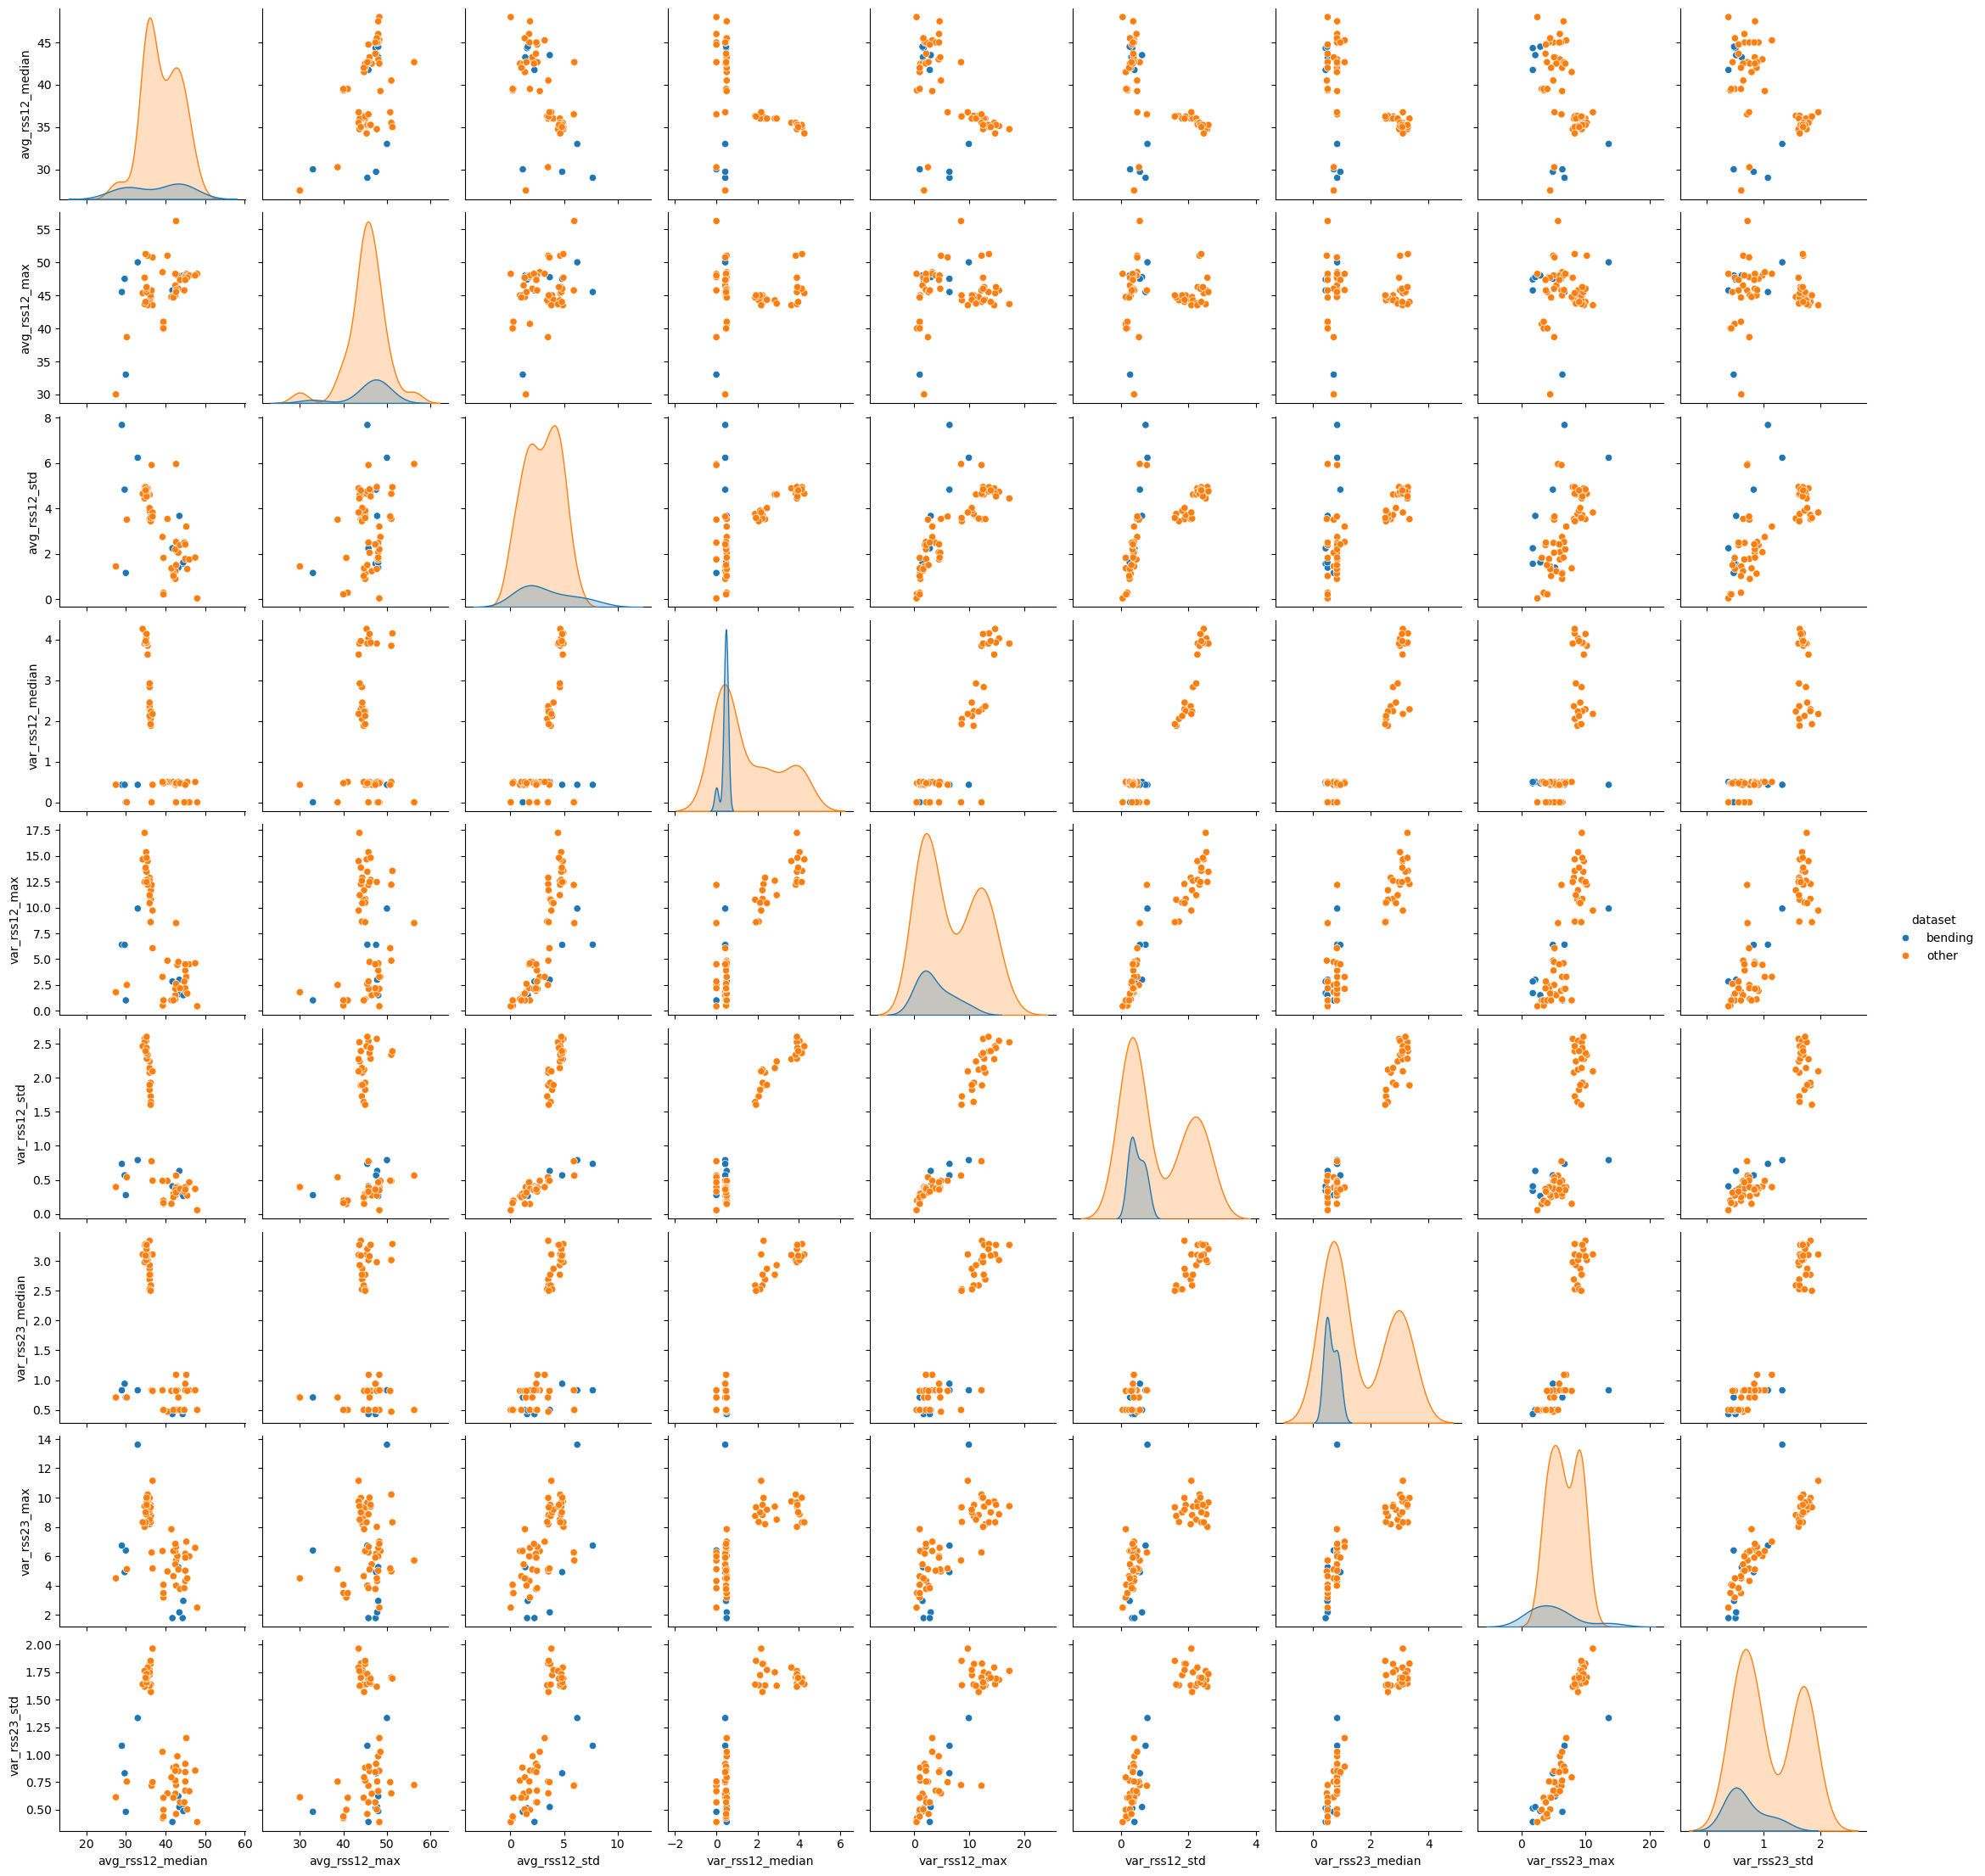

In [18]:
sns.pairplot(data = train_data_subset_agg, vars = ['avg_rss12_median', 'avg_rss12_max', 'avg_rss12_std', 'var_rss12_median', 'var_rss12_max', 'var_rss12_std', 'var_rss23_median', 'var_rss23_max', 'var_rss23_std'], hue = 'dataset')

#### ii. Splitted Plots

In [19]:
train_data['half'] =  (train_data.groupby('instance_number').cumcount() >= train_data.groupby('instance_number')['instance_number'].transform('count') / 2)
train_data.head(3)

,# Columns: time,avg_rss12,var_rss12,avg_rss13,var_rss13,avg_rss23,var_rss23,instance_number,dataset,half
0,0,42.0,0.71,21.25,0.43,30.00,0.00,3,bending,False
1,250,41.5,0.50,20.25,1.48,31.25,1.09,3,bending,False
2,500,41.5,0.50,14.25,1.92,33.00,0.00,3,bending,False


In [20]:
train_data_first_half = train_data[train_data['half'] == False]
train_data_first_half_subset = train_data_first_half[['avg_rss12', 'var_rss12', 'var_rss23', 'instance_number', 'dataset']]
train_data_first_half_subset_agg = train_data_first_half_subset.groupby(['instance_number', 'dataset']).agg(avg_rss12_median_first_half =('avg_rss12', 'median'), avg_rss12_max_first_half = ('avg_rss12', 'max'), avg_rss12_std_first_half = ('avg_rss12', 'std'), var_rss12_median_first_half = ('var_rss12', 'median'), var_rss12_max_first_half = ('var_rss12', 'max'), var_rss12_std_first_half = ('var_rss12', 'std'), var_rss23_median_first_half = ('var_rss23', 'median'), var_rss23_max_first_half = ('var_rss23', 'max'), var_rss23_std_first_half = ('var_rss23', 'std')).reset_index()
train_data_first_half_subset_agg

,instance_number,dataset,avg_rss12_median_first_half,avg_rss12_max_first_half,avg_rss12_std_first_half,var_rss12_median_first_half,var_rss12_max_first_half,var_rss12_std_first_half,var_rss23_median_first_half,var_rss23_max_first_half,var_rss23_std_first_half
0,3,bending,44.500,46.50,1.556971,0.470,1.50,0.329540,0.500,1.79,0.526656
1,4,bending,45.000,47.75,3.473355,0.485,3.00,0.634285,0.765,1.53,0.554542
2,5,bending,42.330,45.75,3.118644,0.500,2.83,0.489595,0.430,1.79,0.411200
3,6,bending,45.000,48.00,1.359836,0.000,1.30,0.314099,0.710,5.26,0.718016
4,7,bending,43.710,45.00,1.281976,0.470,1.30,0.284434,0.470,2.28,0.486847
...,...,...,...,...,...,...,...,...,...,...,...
64,84,other,34.000,45.00,4.874433,4.195,11.78,2.196206,3.110,8.29,1.637310
65,85,other,34.415,44.50,4.872880,4.030,13.47,2.762730,3.255,8.41,1.703098
66,86,other,35.000,43.33,4.758757,4.470,12.47,2.391804,2.980,10.00,1.619767
67,87,other,35.330,44.00,4.272282,3.865,14.82,2.341763,3.270,9.18,1.781928


In [21]:
train_data_second_half = train_data[train_data['half'] == True]
train_data_second_half_subset = train_data_second_half[['avg_rss12', 'var_rss12', 'var_rss23', 'instance_number', 'dataset']]
train_data_second_half_subset_agg = train_data_second_half_subset.groupby(['instance_number', 'dataset']).agg(avg_rss12_median_second_half =('avg_rss12', 'median'), avg_rss12_max_second_half = ('avg_rss12', 'max'), avg_rss12_std_second_half = ('avg_rss12', 'std'), var_rss12_median_second_half = ('var_rss12', 'median'), var_rss12_max_second_half = ('var_rss12', 'max'), var_rss12_std_second_half = ('var_rss12', 'std'), var_rss23_median_second_half = ('var_rss23', 'median'), var_rss23_max_second_half = ('var_rss23', 'max'), var_rss23_std_second_half = ('var_rss23', 'std')).reset_index()
train_data_second_half_subset_agg

,instance_number,dataset,avg_rss12_median_second_half,avg_rss12_max_second_half,avg_rss12_std_second_half,var_rss12_median_second_half,var_rss12_max_second_half,var_rss12_std_second_half,var_rss23_median_second_half,var_rss23_max_second_half,var_rss23_std_second_half
0,3,bending,43.500,47.40,1.557168,0.500,1.70,0.342346,0.000,1.50,0.478528
1,4,bending,42.000,46.00,3.537481,0.500,2.86,0.627915,0.470,2.18,0.491873
2,5,bending,41.500,43.67,0.595920,0.500,1.12,0.273050,0.430,1.50,0.363144
3,6,bending,42.670,46.50,1.058792,0.500,1.58,0.260761,0.500,4.06,0.473445
4,7,bending,44.500,48.00,1.771251,0.500,1.50,0.235493,0.500,2.96,0.487918
...,...,...,...,...,...,...,...,...,...,...,...
64,84,other,34.500,45.33,4.411903,4.320,14.67,2.694219,3.155,8.32,1.646023
65,85,other,35.500,45.50,4.621400,3.740,12.50,2.387460,3.155,9.67,1.758379
66,86,other,35.875,46.00,4.880650,3.880,12.28,2.315929,3.255,8.64,1.691050
67,87,other,35.250,46.25,4.785599,4.070,12.26,2.514203,3.350,9.51,1.598536


In [22]:
merged = train_data_first_half_subset_agg.merge(train_data_second_half_subset_agg, on = ['instance_number', 'dataset'], how = 'inner')

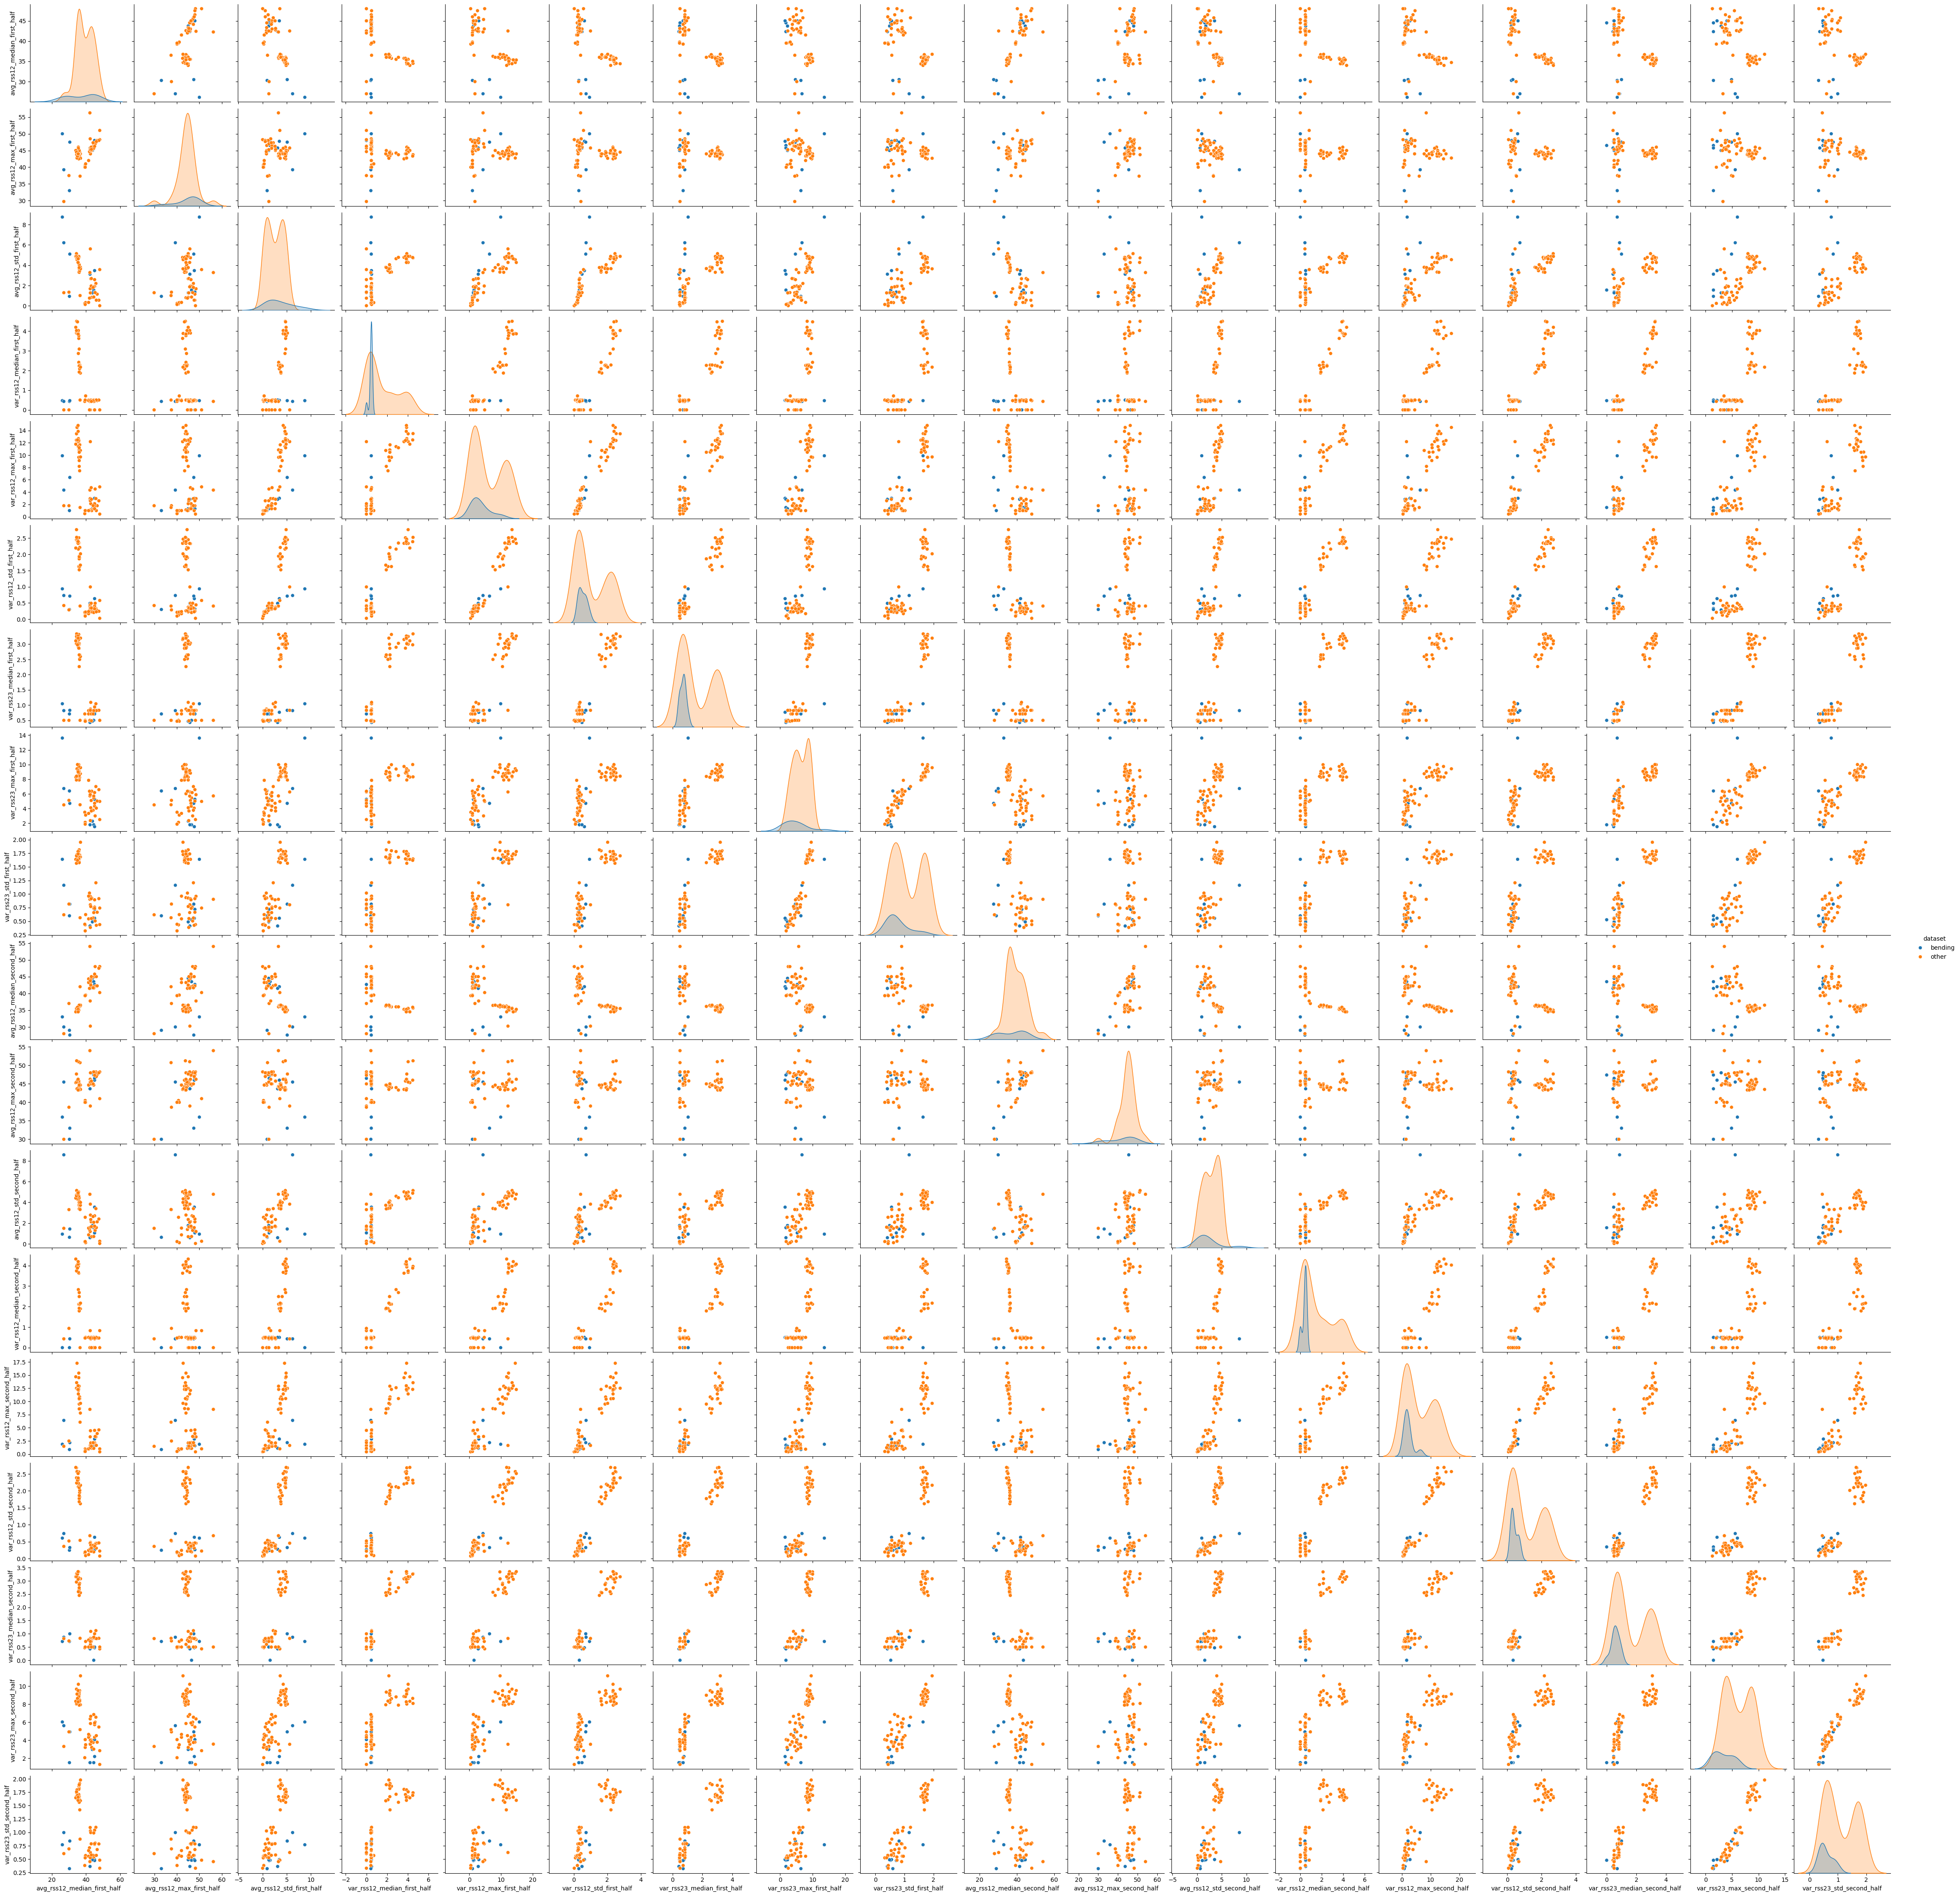

In [133]:
sns.pairplot(data = merged, vars = ['avg_rss12_median_first_half', 'avg_rss12_max_first_half', 'avg_rss12_std_first_half', 'var_rss12_median_first_half', 'var_rss12_max_first_half', 'var_rss12_std_first_half', 'var_rss23_median_first_half', 'var_rss23_max_first_half', 'var_rss23_std_first_half', 'avg_rss12_median_second_half', 'avg_rss12_max_second_half', 'avg_rss12_std_second_half', 'var_rss12_median_second_half', 'var_rss12_max_second_half', 'var_rss12_std_second_half', 'var_rss23_median_second_half', 'var_rss23_max_second_half', 'var_rss23_std_second_half'], hue = 'dataset')

I do not see a considerable difference. 

#### iii. Time Series Segments

In [28]:
train_data_subset = train_data[['avg_rss12', 'var_rss12', 'var_rss23', 'instance_number', 'dataset']]
train_data_subset

,avg_rss12,var_rss12,var_rss23,instance_number,dataset
0,42.00,0.71,0.00,3,bending
1,41.50,0.50,1.09,3,bending
2,41.50,0.50,0.00,3,bending
3,40.75,0.83,0.00,3,bending
4,40.00,0.71,0.43,3,bending
...,...,...,...,...,...
475,34.50,6.18,4.19,88,other
476,25.75,6.02,1.58,88,other
477,31.50,3.35,2.95,88,other
478,33.75,2.77,0.43,88,other


In [36]:
feature_tables = {}
for l in np.arange(1,21,1):
    features = []
    for instance_number, df in train_data_subset.groupby('instance_number'):
        rows = {'instance_number': instance_number, 'dataset': df['dataset'].iloc[0]}
        split_df = np.array_split(df, l)
        for l_split, split_df in enumerate(split_df, start = 1):
            for cols in ['avg_rss12', 'var_rss12', 'var_rss23']:
                rows[f'{cols}_median_split_{l_split}'] = split_df[cols].median()
                rows[f'{cols}_max_split_{l_split}'] = split_df[cols].max()
                rows[f'{cols}_std_split_{l_split}'] = split_df[cols].std()
        features.append(rows)
    feature_tables[l] = pd.DataFrame(features)

/opt/anaconda3/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


We need to perform cross validation within each training fold. Specifically, we need to use stratified cross validaiton because there is a class imbalance. Performing RFE on the entire training set is incorrect because it leaks the actual predictions. 

In [62]:
result_pairs = []

for l in np.arange(1,21,1):
    df = feature_tables[l]
    x = df.drop(columns = {'instance_number', 'dataset'})
    y = df['dataset'].map({'bending': 1, 'other': 0})
    for p in np.arange(1, x.shape[1] + 1):
        pipeline = Pipeline([('feature_selection', RFE(LogisticRegression(max_iter = 1000), n_features_to_select=p)),
            ('model', LogisticRegression(max_iter = 1000))])
        cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
        scores = cross_val_score(pipeline, x, y, cv=cv, scoring='accuracy', n_jobs = -1)
        result_pairs.append((l, p, 1 - scores.mean()))

Exception ignored in: <function ResourceTracker.__del__ at 0x1057fdbc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x1037c9bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x106a71bc0>
Traceback (most recent call last

In [67]:
results = pd.DataFrame(result_pairs, columns=['l', 'p', 'error_rate']).sort_values(by='error_rate').head(3)
results

,l,p,error_rate
159,6,25,0.058242
176,6,42,0.058242
175,6,41,0.058242


Exception ignored in: <function ResourceTracker.__del__ at 0x106911bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x103b71bc0>
Traceback (most recent call last):
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 82, in __del__
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 91, in _stop
  File "/opt/anaconda3/lib/python3.13/multiprocessing/resource_tracker.py", line 116, in _stop_locked
ChildProcessError: [Errno 10] No child processes
Exception ignored in: <function ResourceTracker.__del__ at 0x106f21bc0>
Traceback (most recent call last

The best l,p combination is 6 splits and 25 predictors.

#### iv. Confusion Matrix

In [68]:
results

,l,p,error_rate
159,6,25,0.058242
176,6,42,0.058242
175,6,41,0.058242


In [96]:
df = feature_tables[6]
x = df.drop(columns = {'instance_number', 'dataset'})
y = df['dataset'].map({'bending': 1, 'other': 0})
pipeline = Pipeline([('feature_selection', RFE(LogisticRegression(max_iter = 1000), n_features_to_select=25)),
            ('model', LogisticRegression(max_iter = 1000))])
pipeline.fit(x,y)
y_prob = pipeline.predict_proba(x)[:, 1]
y_pred = pipeline.predict(x)
y_pred

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0])

In [94]:
confusion_matrix(y,y_pred)

array([[60,  0],
       [ 0,  9]])

In [98]:
fpr, tpr, thresholds = roc_curve(y, y_prob)
auc = roc_auc_score(y, y_prob)

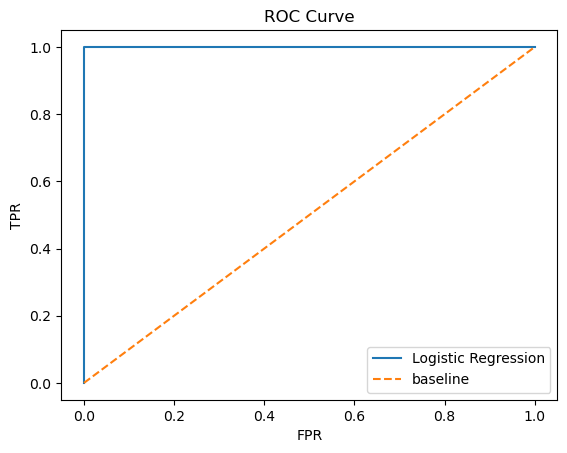

In [109]:
plt.plot(fpr, tpr, label = 'Logistic Regression')
plt.xlabel('FPR')
plt.ylabel('TPR')
plt.title('ROC Curve')
plt.plot([0, 1],[0, 1], linestyle='--', label = 'baseline')
plt.legend()

In [ ]:
rfe = pipeline.named_steps['feature_selection']
model = pipeline.named_steps['model']
selected_features = x.columns[rfe.support_]
selected_features

Index(['avg_rss12_median_split_1', 'avg_rss12_max_split_1',
       'var_rss23_max_split_1', 'avg_rss12_median_split_2',
       'avg_rss12_max_split_2', 'avg_rss12_std_split_2',
       'var_rss12_max_split_2', 'var_rss23_max_split_2',
       'avg_rss12_median_split_3', 'avg_rss12_max_split_3',
       'avg_rss12_std_split_3', 'var_rss23_max_split_3',
       'avg_rss12_median_split_4', 'avg_rss12_max_split_4',
       'var_rss12_max_split_4', 'var_rss23_max_split_4',
       'avg_rss12_median_split_5', 'avg_rss12_max_split_5',
       'avg_rss12_std_split_5', 'var_rss23_median_split_5',
       'var_rss23_max_split_5', 'avg_rss12_median_split_6',
       'avg_rss12_max_split_6', 'var_rss23_median_split_6',
       'var_rss23_max_split_6'],
      dtype='object')

In [90]:
model.coef_[0]

array([-0.2186154 ,  0.18406235,  0.15807542, -0.39613679,  0.63036874,
        0.19312259, -0.46181883, -0.19044883,  0.25583111, -0.23612829,
        0.41249184, -0.51694664, -0.5253082 ,  0.31245118, -0.18003949,
       -0.72988186, -0.38659643,  0.17207618,  0.45200012, -0.1912381 ,
       -0.7425212 , -0.24014303,  0.43101375, -0.19266364, -0.46479654])

In [91]:
model.intercept_[0]

np.float64(2.7241234239335306)

In [ ]:
rfe = pipeline.named_steps['feature_selection']
selected_features = x.columns[rfe.support_]
x_selected = x[selected_features]
x_selected = sm.add_constant(x_selected)
sm_model = sm.Logit(y, x_selected).fit(maxiter=1000)

[ True  True False False False False False  True False  True  True  True
 False  True False False  True False  True  True  True False False False
 False  True False  True  True False False  True False False  True False
  True  True  True False False False  True  True False  True  True False
 False False False  True  True False]
         Current function value: inf
         Iterations: 1000


/opt/anaconda3/lib/python3.13/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/opt/anaconda3/lib/python3.13/site-packages/statsmodels/discrete/discrete_model.py:227: PerfectSeparationWarning: Perfect separation or prediction detected, parameter may not be identified
  warnings.warn(msg, category=PerfectSeparationWarning)
/opt/anaconda3/lib/p

LinAlgError: Singular matrix

#### v. Test Classifier

In [129]:
test_data['dataset'] = test_data['instance_number'].apply(lambda x: 'bending' if x in range(1,14) else 'other')
test_data_subset = test_data[['avg_rss12', 'var_rss12', 'var_rss23', 'instance_number', 'dataset']]
test_data_subset.head(3)

,avg_rss12,var_rss12,var_rss23,instance_number,dataset
0,39.25,0.43,1.3,1,bending
1,39.25,0.43,0.0,1,bending
2,39.25,0.43,0.0,1,bending


In [128]:
test_feature_tables = {}
for l in np.arange(6,7,1):
    features = []
    for instance_number, df in train_data_subset.groupby('instance_number'):
        rows = {'instance_number': instance_number, 'dataset': df['dataset'].iloc[0]}
        split_df = np.array_split(df, l)
        for l_split, split_df in enumerate(split_df, start = 1):
            for cols in ['avg_rss12', 'var_rss12', 'var_rss23']:
                rows[f'{cols}_median_split_{l_split}'] = split_df[cols].median()
                rows[f'{cols}_max_split_{l_split}'] = split_df[cols].max()
                rows[f'{cols}_std_split_{l_split}'] = split_df[cols].std()
        features.append(rows)
    test_feature_tables[l] = pd.DataFrame(features)
test_feature_tables[6]

/opt/anaconda3/lib/python3.13/site-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


,instance_number,dataset,avg_rss12_median_split_1,avg_rss12_max_split_1,avg_rss12_std_split_1,var_rss12_median_split_1,var_rss12_max_split_1,var_rss12_std_split_1,var_rss23_median_split_1,var_rss23_max_split_1,...,var_rss23_std_split_5,avg_rss12_median_split_6,avg_rss12_max_split_6,avg_rss12_std_split_6,var_rss12_median_split_6,var_rss12_max_split_6,var_rss12_std_split_6,var_rss23_median_split_6,var_rss23_max_split_6,var_rss23_std_split_6
0,3,bending,44.500,45.00,1.031429,0.50,1.00,0.268555,0.430,1.50,...,0.447093,43.000,47.25,0.687715,0.500,1.00,0.187812,0.000,1.30,0.241797
1,4,bending,45.000,47.75,3.229635,0.47,3.00,0.594043,0.830,1.50,...,0.534095,41.875,45.00,3.648114,0.500,2.86,0.657484,0.470,1.50,0.457427
2,5,bending,42.000,45.00,2.242549,0.50,1.22,0.353699,0.430,1.30,...,0.257485,41.500,42.50,0.508617,0.500,1.12,0.275106,0.430,1.00,0.270023
3,6,bending,45.000,46.75,0.682991,0.00,1.30,0.256130,0.605,3.04,...,0.314050,42.750,44.25,1.285293,0.500,1.58,0.268304,0.470,4.06,0.681275
4,7,bending,42.500,44.50,0.894612,0.47,1.12,0.297751,0.430,2.28,...,0.622762,44.500,48.00,1.379776,0.470,1.22,0.236492,0.500,1.73,0.381944
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
64,84,other,34.375,45.00,4.860503,4.74,9.76,2.332581,3.395,7.53,...,1.522235,34.670,45.33,4.536265,4.530,13.87,2.711483,3.255,6.80,1.533183
65,85,other,34.500,44.50,4.650889,4.21,13.47,3.147935,3.620,8.41,...,1.698663,35.875,43.75,4.679774,3.670,10.95,2.330906,3.270,8.38,1.780036
66,86,other,34.500,43.33,4.333692,4.24,9.81,2.114076,3.055,10.00,...,1.731460,35.500,44.00,4.649020,4.025,11.67,2.581703,3.670,8.14,1.708332
67,87,other,34.670,42.75,4.111621,3.91,14.82,2.659403,3.020,9.18,...,1.684201,36.225,44.00,4.381385,4.380,11.02,2.450389,3.515,7.18,1.429468


In [130]:
test_df = test_feature_tables[6]
x = test_df.drop(columns = {'instance_number', 'dataset'})
y = test_df['dataset'].map({'bending': 1, 'other': 0})
pipeline = Pipeline([('feature_selection', RFE(LogisticRegression(max_iter = 1000), n_features_to_select=25)),
            ('model', LogisticRegression(max_iter = 1000))])
pipeline.fit(x,y)
y_prob = pipeline.predict_proba(x)[:, 1]
y_pred = pipeline.predict(x)
y_pred

array([1, 1, 1, 1, 1, 1, 1, 1, 1, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0])

In [133]:
accuracy_score(y, y_pred)

1.0

In [134]:
1 - 0.058242

0.941758

This received a 100% accuracy score on the testing dataset. The cross validation accuracy was 94.2%.

#### vi. Separation

Yes, the classes seem to be extremely well seperated, which is causing instabiltiy in the logistic regression parameters. I got a 100% testing accuracy, as well as several warnings about perfect seperation. As a result, the MLE were heading towards infinity and could not converge. This is why I was not able to get p-values as well.

#### vii. Imbalance

From the confusion matrix above, I see class imbalance.

In [ ]:
x

### (b) Binary Classification Using L1-penalized logistic regression

#### i. Time Series Segments

#### ii. Comparison

### (c) Multi-class Classification (The Realistic Case)

#### i. Time Series Segments

#### ii. Naive Bayes

#### ii. Comparison

## 3. ISLR 4.8.3

When we do LDA, one of the core assumptions is that the variance of each predicot remains the same across all classes. Therefore, when we plug in variance in the formula and look at what remains constant for every class, we remove the x^2 value. Since the observation data and variance is the same, that value remains the same. However, in QDA, we do not make this assumption. Therefore, each class has its own variance. Therefore, this means that x^2/(2*variance) is different across each class. The quadratic term remains in the discriminant function, which means it is quadratic rather than linear.

## 4. ISLR 4.8.7

P(Company Issues Dividence | X = 4)

= (P(Issues Dividend) * P(X = 4 | Company Issues Dividend)) / (P(X =4| Issues Dividend) * (P(Company Issues Dividence)) + (P(X = 4 | Company does not issues Dividend)(P(Compay Does Not Issue Dividend)))

f(4) issues dividend = .0403, 
f(4) does not issue dividend = .0532

=.8 * .0403 / ((.0403 * .8) + (0532 * .2))

= .7519